# IaCGen and IaCGen-MAS with DeepSeek-V4-Flash - CloudFormation, 250 scenarios

In [1]:
import sys, re, json, warnings
from math import comb
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sys.path.insert(0, "audit")
import finalize_results as fr
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 80)
FINAL = "../results"
NAME = "CFN_RealAWS_IaCGen_DSV4Flash"
ds = pd.read_csv("../data/cfn_eval_benchmark_real_aws.csv")
ds["row_number"] = ds.row_number.astype(int)
LV = [1, 2, 3, 4, 5]
def load(e):
    r = pd.read_csv(f"{FINAL}/{e}/results_final.csv", low_memory=False)
    r["row_number"] = r.row_number.astype(int)
    r = r[r.row_number.isin(ds.row_number)].merge(ds[["row_number", "difficulty"]], on="row_number")
    r["p"] = r.final_validation_passed.astype(str).str.lower().eq("true")
    r["valid"] = ~r.validity.eq("invalid_environment")
    return r.set_index("row_number").sort_index()
ig = load(NAME)
raw = pd.read_csv("../results/CFN_RealAWS_IaCGen_DSV4Flash/iterative_DSV4Flash_merged_results.csv", low_memory=False)
raw["row_number"] = raw.row_number.astype(int)
raw = raw.set_index("row_number").sort_index()
eh = pd.read_csv("../results/CFN_RealAWS_IaCGen_DSV4Flash/error_history.csv", low_memory=False)
eh["row_number"] = eh.row_number.astype(int)
print(len(ds), "rows;", ds.difficulty.value_counts().sort_index().to_dict())

250 rows; {1: 50, 2: 50, 3: 50, 4: 50, 5: 50}


## Summary

In [2]:
n = len(ig)
tab = pd.DataFrame({
    "rows": n, "passed": int(ig.p.sum()), "valid_fail": int((ig.validity == "valid_fail").sum()), "invalid": int((~ig.valid).sum()),
    "pass_over_rows": round(ig.p.mean(), 3), "pass_over_valid": round(ig[ig.valid].p.mean(), 3),
    "first_attempt_pass": int((ig.p & (ig.iterations_used == 1)).sum()),
    "mean_iterations": round(ig.iterations_used.mean(), 2), "median_iterations": ig.iterations_used.median(),
    "mean_iterations_passed": round(ig[ig.p].iterations_used.mean(), 2),
}, index=[NAME]).T
tab

,CFN_RealAWS_IaCGen_DSV4Flash
rows,250.000
passed,219.000
valid_fail,28.000
invalid,3.000
pass_over_rows,0.876
pass_over_valid,0.887
first_attempt_pass,59.000
mean_iterations,4.800
median_iterations,3.000
mean_iterations_passed,3.360


## Pass rate by difficulty

In [3]:
g = ig.groupby("difficulty")
bylvl = pd.DataFrame({
    "rows": g.size(), "passed": g.p.sum().astype(int), "valid_fail": g.apply(lambda x: int((x.validity == "valid_fail").sum())),
    "invalid": g.apply(lambda x: int((~x.valid).sum())),
    "pass_rate": g.p.mean().round(3),
    "pass_rate_valid": g.apply(lambda x: round(x[x.valid].p.mean(), 3)),
    "first_attempt": g.apply(lambda x: int((x.p & (x.iterations_used == 1)).sum())),
    "mean_iter": g.iterations_used.mean().round(2),
    "mean_iter_passed": g.apply(lambda x: round(x[x.p].iterations_used.mean(), 2)),
    "median_iter": g.iterations_used.median(),
})
bylvl

,rows,passed,valid_fail,invalid,pass_rate,pass_rate_valid,first_attempt,mean_iter,mean_iter_passed,median_iter
difficulty,,,,,,,,,,
1,50,44,5,1,0.88,0.898,19,3.70,2.16,2.0
2,50,46,3,1,0.92,0.939,17,3.88,2.91,2.0
3,50,40,9,1,0.80,0.816,6,5.94,3.68,4.0
4,50,43,7,0,0.86,0.860,11,5.42,3.86,3.0
5,50,46,4,0,0.92,0.920,6,5.06,4.20,4.0


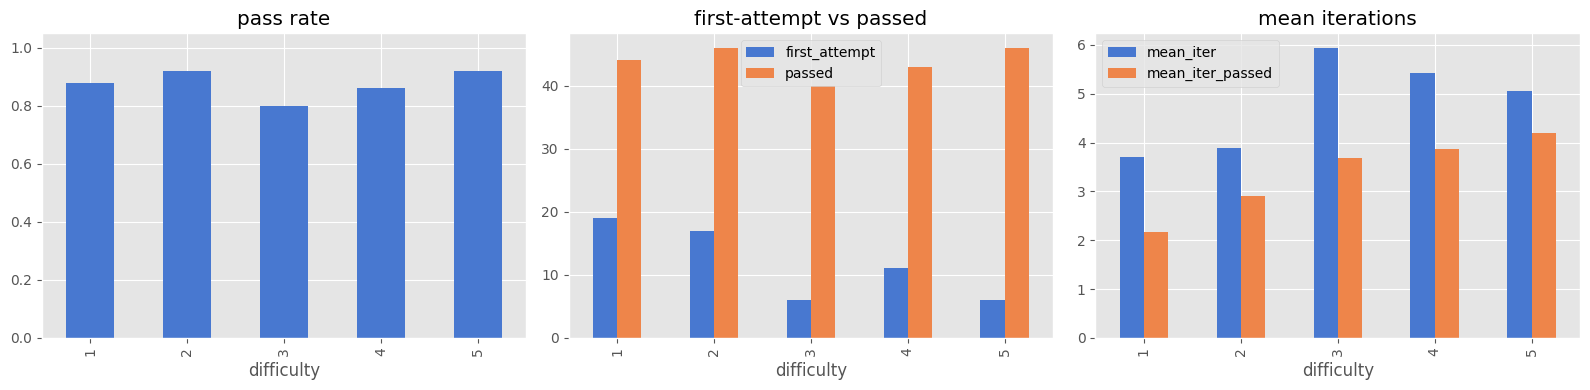

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
bylvl.pass_rate.plot.bar(ax=ax[0], color="C0"); ax[0].set_ylim(0, 1.05); ax[0].set_title("pass rate"); ax[0].set_xlabel("difficulty")
bylvl[["first_attempt", "passed"]].plot.bar(ax=ax[1]); ax[1].set_title("first-attempt vs passed"); ax[1].set_xlabel("difficulty")
bylvl[["mean_iter", "mean_iter_passed"]].plot.bar(ax=ax[2]); ax[2].set_title("mean iterations"); ax[2].set_xlabel("difficulty")
plt.tight_layout(); plt.show()

## By run source

In [5]:
rs = pd.read_csv("../results/CFN_RealAWS_IaCGen_DSV4Flash/row_source.csv").set_index("row_number")
x = ig.join(rs)
sg = x.groupby(["source", "difficulty"])
pd.DataFrame({"rows": sg.size(), "passed": sg.p.sum().astype(int), "pass_rate": sg.p.mean().round(3), "mean_iter": sg.iterations_used.mean().round(2)}).unstack(0)

rows        passed       pass_rate        mean_iter      
source     earlier   new earlier   new   earlier    new   earlier   new
difficulty                                                             
1              NaN  50.0     NaN  44.0       NaN  0.880       NaN  3.70
2              NaN  50.0     NaN  46.0       NaN  0.920       NaN  3.88
3             47.0   3.0    38.0   2.0     0.809  0.667      5.91  6.33
4             40.0  10.0    33.0  10.0     0.825  1.000      6.10  2.70
5             41.0   9.0    38.0   8.0     0.927  0.889      4.90  5.78

## Iterations

In [6]:
N = np.arange(1, 16)
def curve(x):
    return [float((x.p & (x.iterations_used <= k)).sum()) / len(x) for k in N]
cur = pd.DataFrame({"all": curve(ig), **{f"L{l}": curve(ig[ig.difficulty == l]) for l in LV}}, index=N)
cur.index.name = "n"
cur.round(3).T

n,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
all,0.236,0.448,0.584,0.704,0.764,0.788,0.796,0.808,0.82,0.832,0.836,0.856,0.86,0.868,0.876
L1,0.380,0.620,0.760,0.820,0.840,0.860,0.860,0.880,0.88,0.880,0.880,0.880,0.88,0.880,0.880
L2,0.340,0.560,0.660,0.760,0.820,0.860,0.880,0.880,0.88,0.880,0.880,0.900,0.90,0.920,0.920
L3,0.120,0.340,0.460,0.640,0.720,0.720,0.720,0.740,0.76,0.760,0.760,0.760,0.78,0.780,0.800
L4,0.220,0.420,0.560,0.620,0.680,0.700,0.720,0.740,0.78,0.800,0.800,0.840,0.84,0.860,0.860
L5,0.120,0.300,0.480,0.680,0.760,0.800,0.800,0.800,0.80,0.840,0.860,0.900,0.90,0.900,0.920


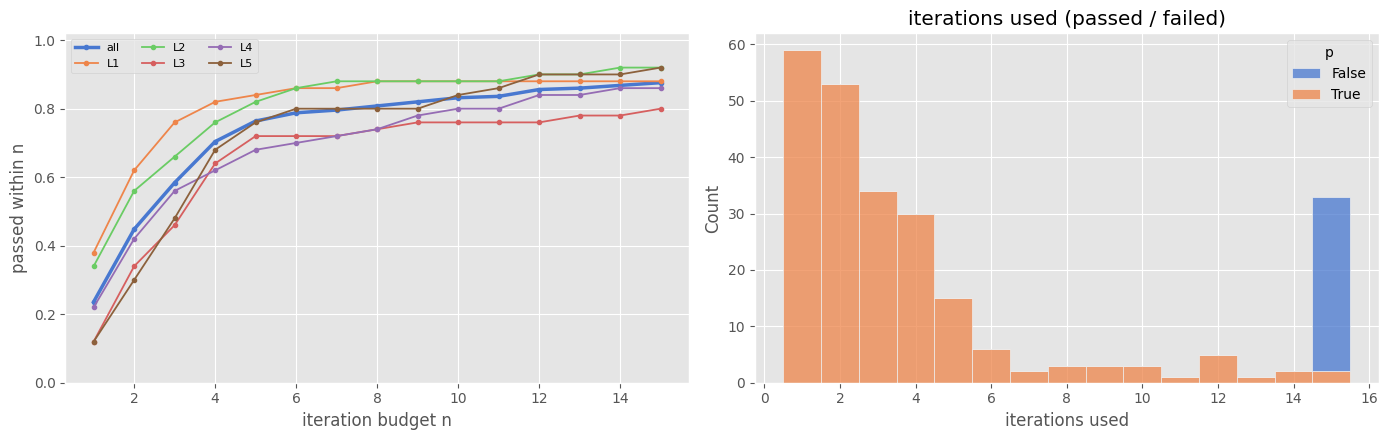

iterations_used,1,2,3-4,5-8,9-15
difficulty,,,,,
1,19,12,10,3,0
2,17,11,10,6,2
3,6,11,15,5,3
4,11,10,10,6,6
5,6,9,19,6,6


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for c in cur.columns:
    ax[0].plot(cur.index, cur[c], marker="o", ms=3, lw=2.5 if c == "all" else 1.3, label=c)
ax[0].set_xlabel("iteration budget n"); ax[0].set_ylabel("passed within n"); ax[0].set_ylim(0, 1.02); ax[0].legend(ncol=3, fontsize=8)
sns.histplot(data=ig.reset_index(), x="iterations_used", hue="p", multiple="stack", discrete=True, ax=ax[1])
ax[1].set_xlabel("iterations used"); ax[1].set_title("iterations used (passed / failed)")
plt.tight_layout(); plt.show()
dist = ig[ig.p].groupby(["difficulty", pd.cut(ig[ig.p].iterations_used, [0, 1, 2, 4, 8, 15], labels=["1", "2", "3-4", "5-8", "9-15"])]).size().unstack(fill_value=0)
dist

In [8]:
rows = []
for k in (1, 2, 3, 5, 8, 15):
    rows.append({"n": k, **{c: round(cur.loc[k, c], 3) for c in cur.columns}})
pd.DataFrame(rows).set_index("n")

,all,L1,L2,L3,L4,L5
n,,,,,,
1,0.236,0.38,0.34,0.12,0.22,0.12
2,0.448,0.62,0.56,0.34,0.42,0.30
3,0.584,0.76,0.66,0.46,0.56,0.48
5,0.764,0.84,0.82,0.72,0.68,0.76
8,0.808,0.88,0.88,0.74,0.74,0.80
15,0.876,0.88,0.92,0.80,0.86,0.92


## Feedback levels and failing stages

In [9]:
lvl = raw.highest_feedback_level.fillna("none").replace("", "none")
pd.crosstab(raw.join(ig[["difficulty"]]).difficulty, lvl)

highest_feedback_level,moderate,none
difficulty,,
1,31,19
2,33,17
3,44,6
4,39,11
5,44,6


In [10]:
fail = raw.join(ig[["difficulty", "validity", "p"]])
fail = fail[~fail.p]
pd.crosstab(fail.difficulty, fail.failed_at_stage.fillna("-"), margins=True)

failed_at_stage,deployment,syntax_validation,yaml_validation,All
difficulty,,,,
1,4,2,0,6
2,2,2,0,4
3,5,4,1,10
4,3,4,0,7
5,4,0,0,4
All,18,12,1,31


## Error history

In [11]:
eh["env"] = eh.error_message.fillna("").map(lambda s: bool(fr.ENV_RE.search(s)))
perrow = eh.groupby("row_number").agg(records=("error_stage", "size"), stages=("error_stage", lambda s: s.value_counts().to_dict()), env=("env", "sum"))
perrow = perrow.join(ig[["difficulty", "p", "iterations_used", "validity"]])
perrow.groupby("difficulty").agg(rows_with_errors=("records", "size"), records=("records", "sum"), mean_records=("records", "mean"), env_records=("env", "sum")).round(2)

,rows_with_errors,records,mean_records,env_records
difficulty,,,,
1,31,253,8.16,18
2,33,500,15.15,4
3,44,782,17.77,15
4,40,932,23.30,6
5,44,949,21.57,1


In [12]:
print(eh.error_stage.value_counts().to_dict(), "| env-like records:", int(eh.env.sum()), "of", len(eh))
def sig(s):
    s = re.sub(r"\s+", " ", str(s))
    m = re.search(r"(\[?E\d{4}\]?|HandlerErrorCode: \w+|already exists|not authorized|Additional properties|is a required property|is not of type|does not exist|Invalid[A-Za-z ]+)", s)
    return m.group(0)[:60] if m else s[:60]
eh["sig"] = eh.error_message.map(sig)
eh.groupby(["error_stage", "sig"]).size().sort_values(ascending=False).head(18)

{'syntax_validation': 2063, 'deployment': 1280, 'yaml_validation': 73} | env-like records: 44 of 3416


error_stage        sig                                                         
deployment         Resource creation cancelled                                     557
syntax_validation  is a required property                                          350
                   Additional properties                                           301
                   is not of type                                                  151
deployment         An error occurred (ValidationError) when calling the CreateS     94
                   HandlerErrorCode: InvalidRequest                                 84
                   Template error: Template error: invalid CIDR block size 24       81
                   does not exist                                                   57
                   HandlerErrorCode: GeneralServiceException                        54
                   HandlerErrorCode: NotStabilized                                  49
                   Invalid request provided       

In [13]:
f = perrow[~perrow.p].sort_values("difficulty", ascending=False).copy()
last = eh.sort_values("timestamp").groupby("row_number").tail(1).set_index("row_number").error_message.str.replace(r"\s+", " ", regex=True).str[:140]
f["last_error"] = last
f[["difficulty", "validity", "iterations_used", "records", "stages", "env", "last_error"]]

,difficulty,validity,iterations_used,records,stages,env,last_error
row_number,,,,,,,
257,5,valid_fail,15,36,"{'syntax_validation': 19, 'deployment': 17}",0,"Resource handler returned message: ""The state machine IAM Role is not author..."
197,5,valid_fail,15,80,"{'deployment': 76, 'syntax_validation': 4}",0,Template error: Template error: invalid CIDR block size 24
175,5,valid_fail,15,105,"{'deployment': 61, 'syntax_validation': 44}",0,Validation failed with 7 error(s). Call DescribeEvents to retrieve the full ...
174,5,valid_fail,15,43,"{'deployment': 35, 'syntax_validation': 8}",0,"Resource handler returned message: ""Unable to download from S3 location (Buc..."
152,4,valid_fail,15,47,{'syntax_validation': 47},0,Additional properties are not allowed ('ResourceSelection' was unexpected)
150,4,valid_fail,15,29,{'syntax_validation': 29},0,'LogSchemaVersion' is a required property
127,4,valid_fail,15,96,"{'syntax_validation': 87, 'deployment': 6, 'yaml_validation': 3}",0,'PolicyDocument' is a required property
125,4,valid_fail,15,61,"{'deployment': 55, 'syntax_validation': 6}",0,"Resource handler returned message: ""Resource of type 'AWS::EC2::Instance' wi..."
121,4,valid_fail,15,21,"{'syntax_validation': 9, 'deployment': 9, 'yaml_validation': 3}",0,Validation failed with 1 error(s). Call DescribeEvents to retrieve the full ...


## Comparison on the same rows

In [14]:
SYS = {"IaCGen": NAME, "IaCGen-MAS": "CFN_RealAWS_DSV4F"}
R = {k: load(v) for k, v in SYS.items()}
cmp = pd.DataFrame({k: {**{f"L{l}": f"{int(r[r.difficulty == l].p.sum())}/{(r.difficulty == l).sum()}" for l in LV},
                         "all": f"{int(r.p.sum())}/{len(r)}", "rate": round(r.p.mean(), 3),
                         "first_attempt": int((r.p & (r.iterations_used == 1)).sum()), "mean_iter": round(r.iterations_used.mean(), 2)}
                    for k, r in R.items()}).T
cmp

,L1,L2,L3,L4,L5,all,rate,first_attempt,mean_iter
IaCGen,44/50,46/50,40/50,43/50,46/50,219/250,0.876,59,4.8
IaCGen-MAS,48/50,50/50,50/50,50/50,49/50,247/250,0.988,48,3.84


In [15]:
def mcnemar(a, b):
    ra, rb = R[a], R[b]
    idx = [i for i in ra.index if i in rb.index and ra.loc[i, "valid"] and rb.loc[i, "valid"]]
    x, y = ra.loc[idx, "p"], rb.loc[idx, "p"]
    n10, n01 = int((x & ~y).sum()), int((~x & y).sum())
    n = n10 + n01
    pv = min(1.0, 2 * sum(comb(n, i) for i in range(0, min(n10, n01) + 1)) / 2 ** n) if n else 1.0
    return {"common_valid": len(idx), "only_a": n10, "only_b": n01, "p": round(pv, 3),
            "mean_iter_a_minus_b": round((ra.loc[idx, "iterations_used"] - rb.loc[idx, "iterations_used"]).mean(), 2)}
ref = "IaCGen"
pd.DataFrame({k: mcnemar(ref, k) for k in SYS if k != ref}).T

,common_valid,only_a,only_b,p,mean_iter_a_minus_b
IaCGen-MAS,247.0,1.0,27.0,0.0,0.92


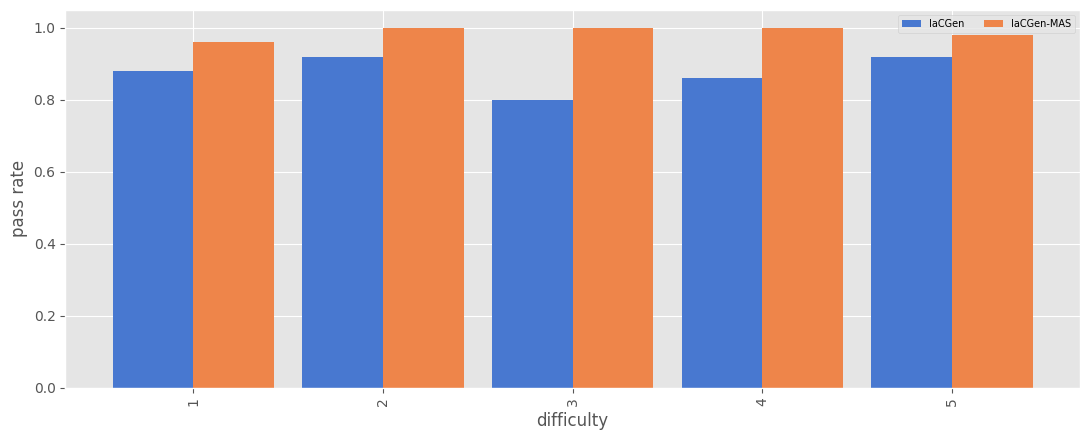

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.5))
plot = pd.DataFrame({k: r.groupby("difficulty").p.mean() for k, r in R.items()})
plot.plot.bar(ax=ax, width=0.85); ax.set_ylim(0, 1.05); ax.set_ylabel("pass rate"); ax.set_xlabel("difficulty"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## Security and coverage (post-hoc)

In [17]:
def audits(e):
    c = pd.read_csv(f"result/final/Coverage_{e}.csv"); t = pd.read_csv(f"result/final/Trivy_{e}.csv")
    r = pd.read_csv(f"{FINAL}/{e}/results_final.csv", low_memory=False)
    r["row_number"] = r.row_number.astype(int)
    c["row_number"] = c.row_number.astype(int)
    t = t.merge(r[["run_id", "row_number"]], on="run_id", how="left")
    return c, t
out = {}
for k, e in (("IaCGen", NAME), ("IaCGen-MAS", "CFN_RealAWS_DSV4F")):
    c, t = audits(e)
    c = c[c.row_number.isin(ds.row_number)]; t = t[t.row_number.isin(ds.row_number)]
    ch = (t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) == 0
    out[k] = {"rows": len(c), "coverage_pct": round(c.coverage_pct.mean(), 1), "accuracy_pct": round(c.accuracy_pct.mean(), 1),
              "no_critical_high": round(ch.mean(), 3), "no_finding_any_severity": round(t.trivy_passed.mean(), 3),
              "findings_per_template": round(t.total_failed.mean(), 2)}
pd.DataFrame(out).T

,rows,coverage_pct,accuracy_pct,no_critical_high,no_finding_any_severity,findings_per_template
IaCGen,250.0,85.4,87.1,0.812,0.412,2.00
IaCGen-MAS,250.0,86.0,81.3,0.992,0.408,1.71


In [18]:
c, t = audits(NAME)
cc = c.merge(ds[["row_number", "difficulty"]], on="row_number")
tt = t.merge(ds[["row_number", "difficulty"]], on="row_number")
tt["ch_free"] = (tt.severity_critical_failed.fillna(0) + tt.severity_high_failed.fillna(0)) == 0
pd.DataFrame({"coverage_pct": cc.groupby("difficulty").coverage_pct.mean().round(1), "accuracy_pct": cc.groupby("difficulty").accuracy_pct.mean().round(1),
              "no_critical_high": tt.groupby("difficulty").ch_free.mean().round(3), "no_finding_any": tt.groupby("difficulty").trivy_passed.mean().round(3),
              "findings_per_template": tt.groupby("difficulty").total_failed.mean().round(2)})

,coverage_pct,accuracy_pct,no_critical_high,no_finding_any,findings_per_template
difficulty,,,,,
1,96.1,89.4,0.88,0.54,1.10
2,82.4,81.7,0.92,0.50,1.70
3,84.8,86.8,0.88,0.44,1.44
4,80.2,85.8,0.68,0.32,2.64
5,83.3,91.9,0.70,0.26,3.14


## Numbers for the thesis

In [19]:
ma = load("CFN_RealAWS_DSV4F")
dif = ds.set_index("row_number").difficulty
def trivy(e):
    t = pd.read_csv(f"result/final/Trivy_{e}.csv")
    r = pd.read_csv(f"{FINAL}/{e}/results_final.csv", usecols=["run_id", "row_number"], low_memory=False)
    t = t.merge(r, on="run_id", how="left")
    t = t[t.error.isna()] if "error" in t else t
    t["row_number"] = t.row_number.astype(int)
    return t.drop_duplicates("row_number").set_index("row_number")
def cover(e):
    c = pd.read_csv(f"result/final/Coverage_{e}.csv")
    c["row_number"] = c.row_number.astype(int)
    return c.drop_duplicates("row_number").set_index("row_number")
T = {"IaCGen": trivy(NAME), "IaCGen-MAS": trivy("CFN_RealAWS_DSV4F")}
CV = {"IaCGen": cover(NAME), "IaCGen-MAS": cover("CFN_RealAWS_DSV4F")}
severe = lambda t: (t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) > 0
ig_severe = severe(T["IaCGen"]).reindex(ig.index).fillna(True)
P = {"IaCGen, deploys": ig.p, "IaCGen, deploys and secure": ig.p & ~ig_severe, "IaCGen-MAS, deploys and secure": ma.p}
IT = {"IaCGen, deploys": ig.iterations_used, "IaCGen, deploys and secure": ig.iterations_used, "IaCGen-MAS, deploys and secure": ma.iterations_used.clip(upper=15)}
summary = pd.DataFrame({k: {"passed": int(p.sum()), "pass_%": round(100 * p.mean(), 1),
                            **{f"L{l}_%": round(100 * p[dif.reindex(p.index) == l].mean(), 1) for l in LV},
                            **{f"p@{n}_%": round(100 * (p & (IT[k] <= n)).mean(), 1) for n in (1, 3, 5, 10, 15)},
                            "iters_to_pass_mean": round(IT[k][p].mean(), 2), "iters_to_pass_median": IT[k][p].median()} for k, p in P.items()}).T
def mcn(a, b):
    a, b = a.reindex(ds.row_number).fillna(False), b.reindex(ds.row_number).fillna(False)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum()); n = n10 + n01
    pv = min(1.0, 2 * sum(comb(n, i) for i in range(0, min(n10, n01) + 1)) / 2 ** n) if n else 1.0
    return {"only_IaCGen-MAS": n10, "only_IaCGen": n01, "p": pv}
tests = pd.DataFrame({"against IaCGen, deploys": mcn(ma.p, P["IaCGen, deploys"]), "against IaCGen, deploys and secure": mcn(ma.p, P["IaCGen, deploys and secure"])}).T
both = ma.p & ig.p
common = pd.DataFrame({"both pass": {"scenarios": int(both.sum()), "IaCGen_iters_mean": round(ig.iterations_used[both].mean(), 2),
                                     "IaCGen-MAS_iters_mean": round(ma.iterations_used[both].mean(), 2)}}).T
def sec_row(t):
    out = {"templates": len(t), "pol": round(100 * (t.total_passed / t.total_checks.replace(0, np.nan)).mean(), 1), "clean": round(100 * (t.total_failed == 0).mean(), 1)}
    for s, k in (("critical", "crit"), ("high", "high"), ("medium", "med"), ("low", "low")):
        out[k] = round(100 * t[f"severity_{s}_passed"].sum() / t[f"severity_{s}_eval"].sum(), 1)
    out["with_critical_or_high_%"] = round(100 * severe(t).mean(), 1)
    out["with_medium_or_low_%"] = round(100 * ((t.severity_medium_failed.fillna(0) + t.severity_low_failed.fillna(0)) > 0).mean(), 1)
    return out
security = pd.DataFrame({k: sec_row(t) for k, t in T.items()}).T
security.loc["IaCGen", "deployed_with_critical_or_high"] = int((ig.p & ig_severe).sum())
def cov_row(c):
    return {"generated": round(c.total_generated_resources.mean(), 2), "extra": round(c.extra_resources.mean(), 2), "missing": round(c.missing_resources.mean(), 2),
            "ratio": round((c.total_generated_resources / c.total_required_resources.replace(0, np.nan)).mean(), 2),
            "with_extra_%": round(100 * (c.extra_resources > 0).mean(), 1), "recall": round(c.coverage_pct.mean(), 1), "precision": round(c.accuracy_pct.mean(), 1)}
resources = pd.DataFrame({k: cov_row(c) for k, c in CV.items()}).T
out = pd.concat({"pass": summary, "paired": tests, "common": common, "security": security, "resources": resources}, names=["table", "row"])
out.to_csv("result/final/IaCGen_vs_MAS_DSV4F_numbers.csv")
out


passed  pass_%  L1_%   L2_%   L3_%   L4_%  L5_%  p@1_%  p@3_%  p@5_%  p@10_%  p@15_%  iters_to_pass_mean  iters_to_pass_median  only_IaCGen-MAS  only_IaCGen             p  \
table     row                                                                                                                                                                                                              
pass      IaCGen, deploys                      219.0    87.6  88.0   92.0   80.0   86.0  92.0   23.6   58.4   76.4    83.2    87.6                3.36                   2.0              NaN          NaN           NaN   
          IaCGen, deploys and secure           181.0    72.4  76.0   88.0   72.0   60.0  66.0   20.0   48.8   63.2    68.8    72.4                3.31                   2.0              NaN          NaN           NaN   
          IaCGen-MAS, deploys and secure       247.0    98.8  96.0  100.0  100.0  100.0  98.0   19.2   62.4   80.0    93.2    98.8                3.71                   3.0              NaN          NaN           NaN   
paired    against IaCGen, deploys                NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN             29.0          1.0  5.774200e-08   
          against IaCGen, deploys and secure     NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN             67.0          1.0  4.675622e-19   
common    both pass                              NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN              NaN          NaN           NaN   
security  IaCGen                                 NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN              NaN          NaN           NaN   
          IaCGen-MAS                             NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN              NaN          NaN           NaN   
resources IaCGen                                 NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN              NaN          NaN           NaN   
          IaCGen-MAS                             NaN     NaN   NaN    NaN    NaN    NaN   NaN    NaN    NaN    NaN     NaN     NaN                 NaN                   NaN              NaN          NaN           NaN   

                                              scenarios  IaCGen_iters_mean  IaCGen-MAS_iters_mean  templates   pol  clean   crit  high   med   low  with_critical_or_high_%  with_medium_or_low_%  \
table     row                                                                                                                                                                                       
pass      IaCGen, deploys                           NaN                NaN                    NaN        NaN   NaN    NaN    NaN   NaN   NaN   NaN                      NaN                   NaN   
          IaCGen, deploys and secure                NaN                NaN                    NaN        NaN   NaN    NaN    NaN   NaN   NaN   NaN                      NaN                   NaN   
          IaCGen-MAS, deploys and secure            NaN                NaN                    NaN        NaN   NaN    NaN    NaN   NaN   NaN   NaN                      NaN                   NaN   
paired    against IaCGen, deploys                   NaN                NaN                    NaN        NaN   NaN    NaN    NaN   NaN   NaN   NaN                      NaN                   NaN   
          against IaCGen, deploys and secure        NaN                NaN                    NaN        NaN   NaN    NaN    NaN   NaN   NaN   NaN                      NaN                   NaN   
common    both pass       